In [1]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import random
from src.data.io_utils import read_tif_image, convert_image_to_array

In [2]:
images_patches = Path("/mnt/x/donnees/pachs_64_3classes_filtered/temp/images")
masks_patches = Path("/mnt/x/donnees/pachs_64_3classes_filtered/temp/masks")

print(f"Images existent: {images_patches.exists()}")
print(f"Masks existent: {masks_patches.exists()}")

Images existent: True
Masks existent: True


In [3]:
image_files = sorted(images_patches.glob("*.tif"))
mask_files = sorted(masks_patches.glob("*.tif"))

print(f"Total patches: {len(image_files)}")
print(f"Total masks: {len(mask_files)}")

# Sélectionner 2500 patches aléatoires
SAMPLE_SIZE = 2500
random.seed(42)
selected_indices = random.sample(range(len(image_files)), min(SAMPLE_SIZE, len(image_files)))

print(f"Patches sélectionnés: {len(selected_indices)}")

Total patches: 2550
Total masks: 2550
Patches sélectionnés: 2500


In [4]:
def show_patch_3class(image_path, mask_path, slice_idx=None):
    image_sitk = read_tif_image(str(image_path))
    mask_sitk = read_tif_image(str(mask_path))
    
    image = convert_image_to_array(image_sitk)
    mask = convert_image_to_array(mask_sitk)
    
    if slice_idx is None:
        slice_idx = image.shape[0] // 2
    
    img_slice = image[slice_idx, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    
    mask_slice = mask[slice_idx, :, :]
    
    rgb_mask = np.zeros((mask_slice.shape[0], mask_slice.shape[1], 3), dtype=np.float32)
    rgb_mask[mask_slice == 0] = [0, 0, 0]
    rgb_mask[mask_slice == 1] = [1, 0, 0]
    rgb_mask[mask_slice == 2] = [0, 1, 0]
    
    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay[mask_slice == 1, 0] = 1
    overlay[mask_slice == 1, 1] = 0
    overlay[mask_slice == 1, 2] = 0
    overlay[mask_slice == 2, 0] = 0
    overlay[mask_slice == 2, 1] = 1
    overlay[mask_slice == 2, 2] = 0
    
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    
    axes[0].imshow(img_slice, cmap='gray')
    axes[0].set_title(f'Image - Slice {slice_idx}')
    axes[0].axis('off')
    
    axes[1].imshow(rgb_mask)
    axes[1].set_title('Mask 3 Classes')
    axes[1].axis('off')
    
    axes[2].imshow(overlay)
    axes[2].set_title('Superposition')
    axes[2].axis('off')
    
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='black', label='Fond (0)'),
        Patch(facecolor='red', label='Neurones (1)'),
        Patch(facecolor='green', label='Vaisseaux (2)')
    ]
    axes[2].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))
    
    plt.suptitle(f'{image_path.name}')
    plt.tight_layout()
    plt.show()
    
    print(f"  Classe 0: {(mask == 0).sum():,}")
    print(f"  Classe 1: {(mask == 1).sum():,}")
    print(f"  Classe 2: {(mask == 2).sum():,}")

Visualisation de patches aléatoires
----------------------------------------

--- Patch 26: sample_001000028.tif ---


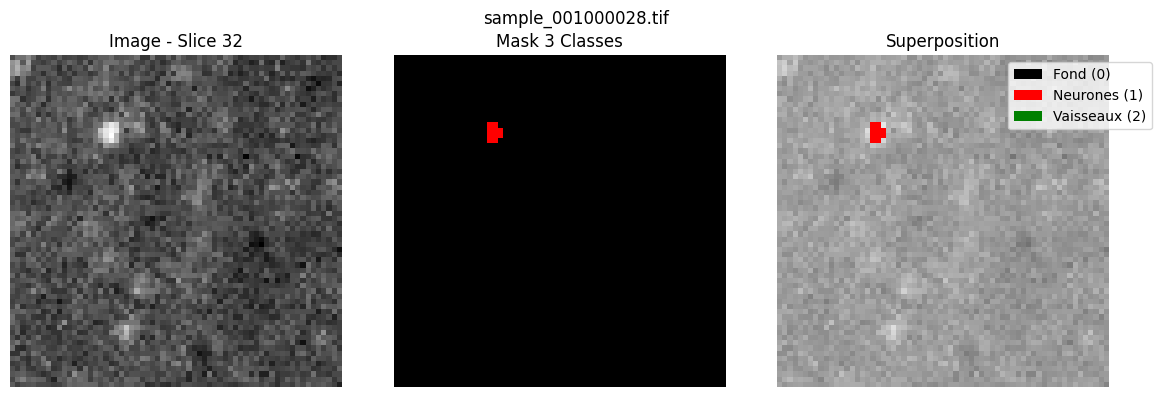

  Classe 0: 260,986
  Classe 1: 1,158
  Classe 2: 0

--- Patch 1444: sample_020000182.tif ---


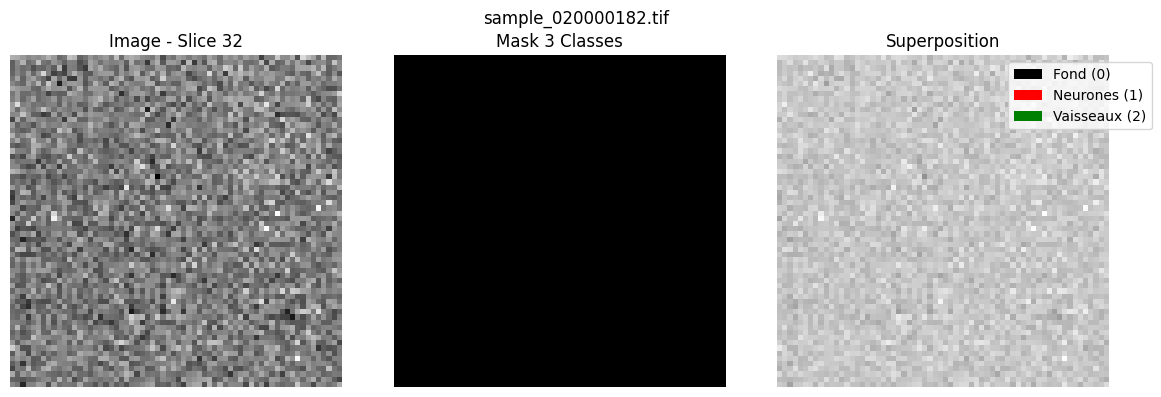

  Classe 0: 262,125
  Classe 1: 19
  Classe 2: 0

--- Patch 2132: sample_024000137.tif ---


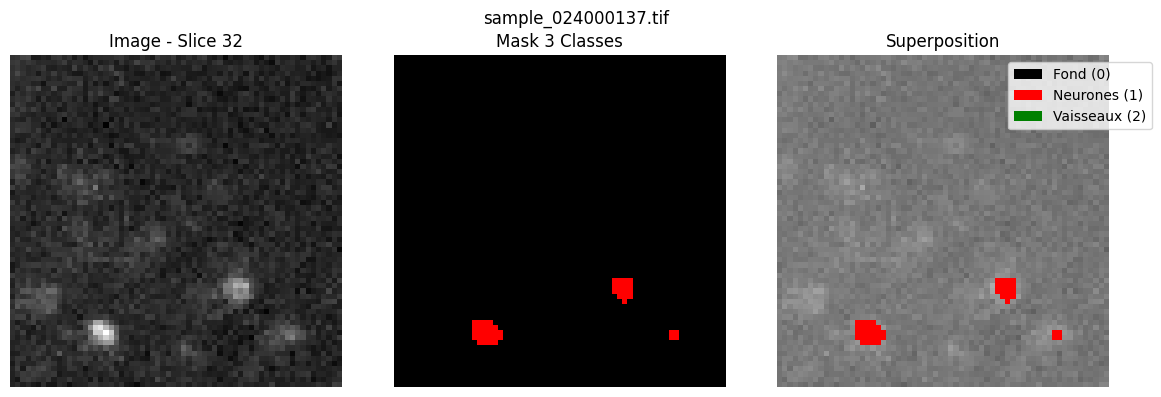

  Classe 0: 260,434
  Classe 1: 1,710
  Classe 2: 0

--- Patch 164: sample_002000037.tif ---


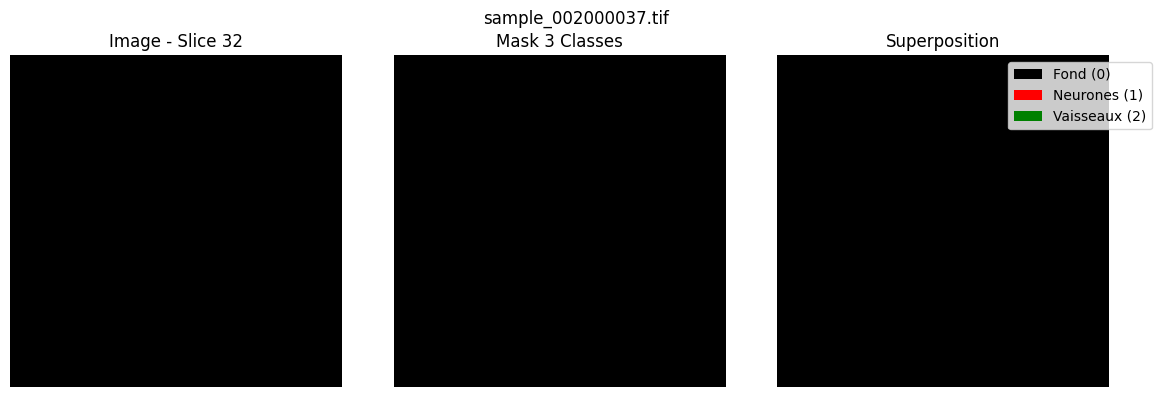

  Classe 0: 261,863
  Classe 1: 281
  Classe 2: 0

--- Patch 256: sample_004000005.tif ---


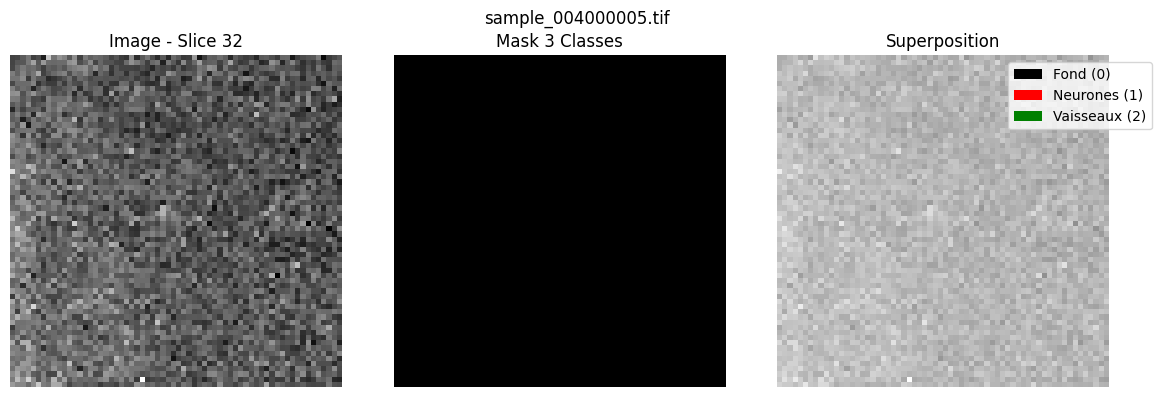

  Classe 0: 261,026
  Classe 1: 1,118
  Classe 2: 0

--- Patch 1351: sample_020000054.tif ---


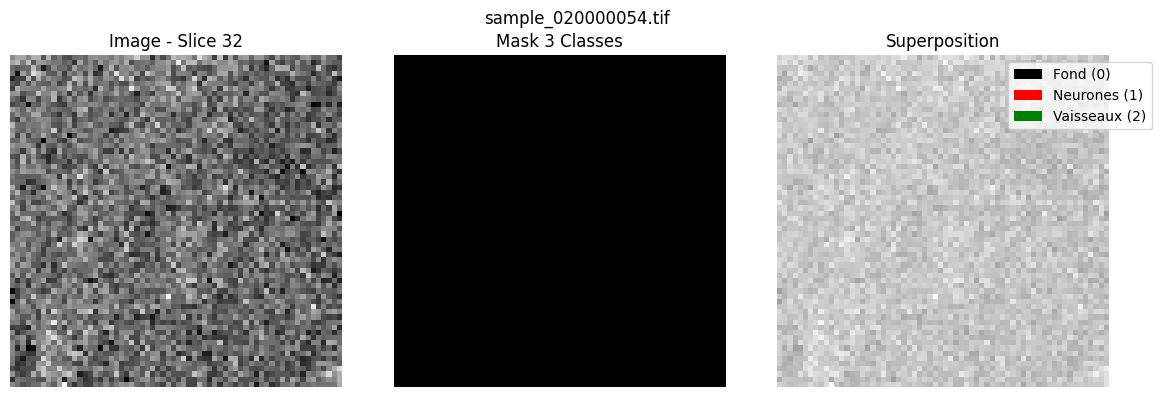

  Classe 0: 262,098
  Classe 1: 46
  Classe 2: 0

--- Patch 1394: sample_020000112.tif ---


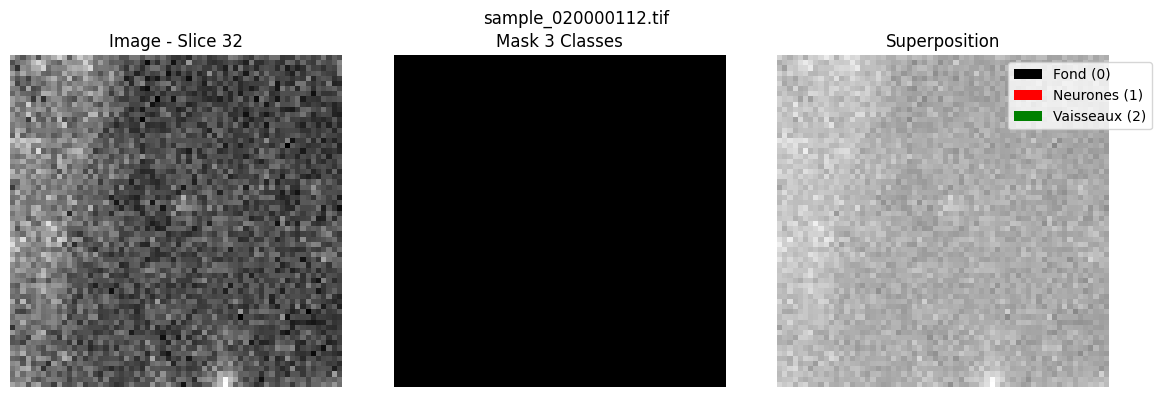

  Classe 0: 261,952
  Classe 1: 192
  Classe 2: 0

--- Patch 448: sample_005000168.tif ---


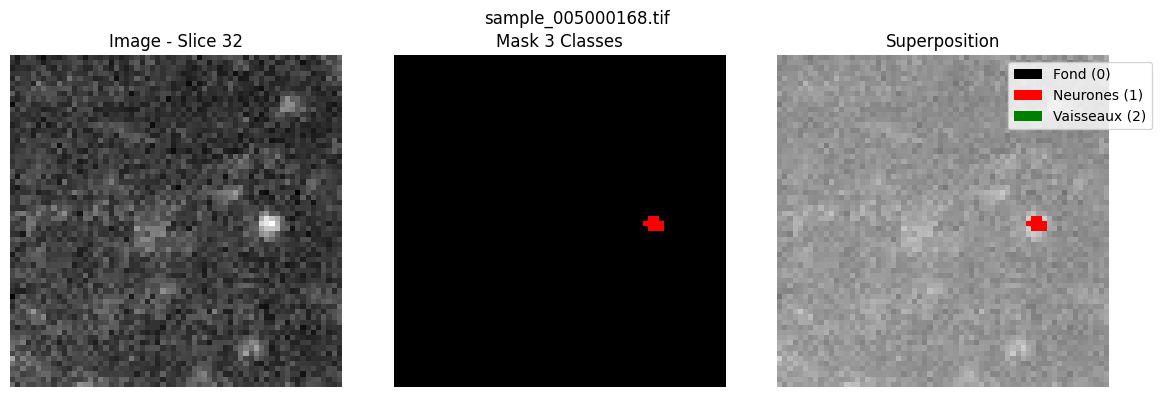

  Classe 0: 259,841
  Classe 1: 2,303
  Classe 2: 0

--- Patch 236: sample_003000057.tif ---


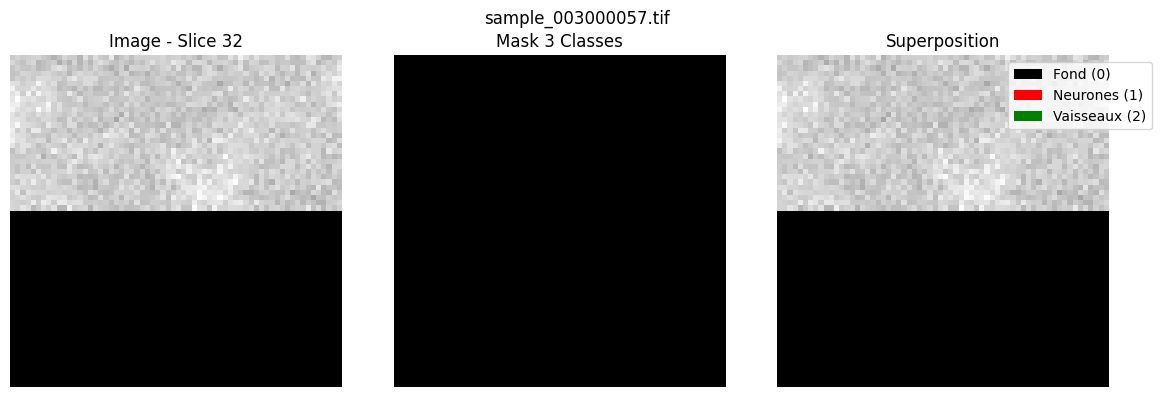

  Classe 0: 262,144
  Classe 1: 0
  Classe 2: 0

--- Patch 1365: sample_020000071.tif ---


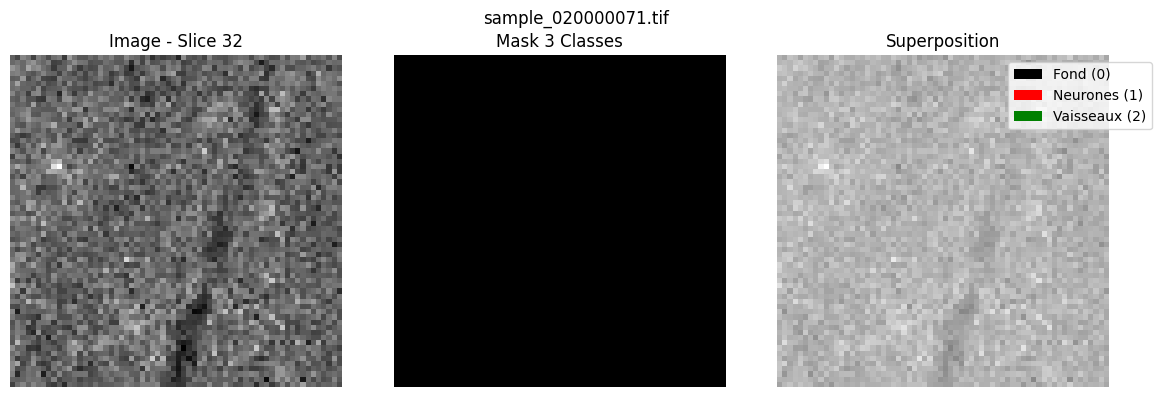

  Classe 0: 262,123
  Classe 1: 21
  Classe 2: 0

--- Patch 511: sample_006000016.tif ---


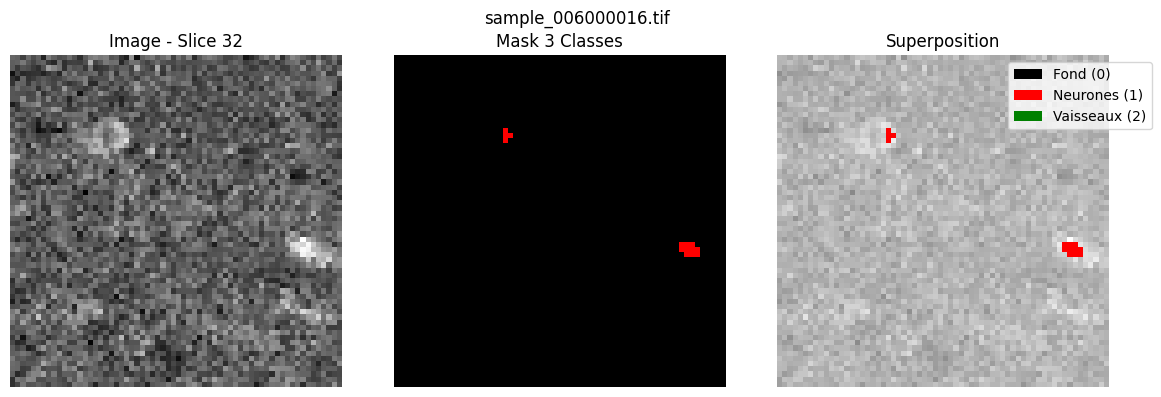

  Classe 0: 261,912
  Classe 1: 232
  Classe 2: 0

--- Patch 988: sample_014000054.tif ---


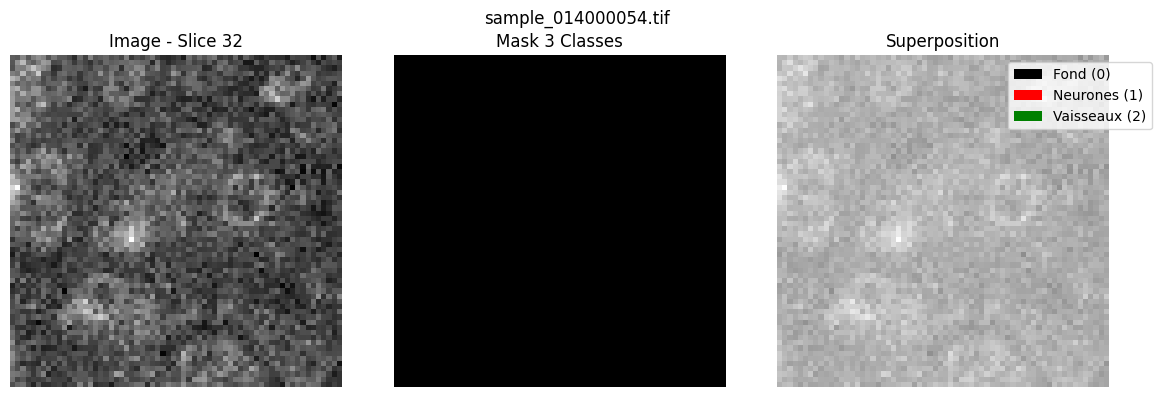

  Classe 0: 261,833
  Classe 1: 311
  Classe 2: 0

--- Patch 2095: sample_024000100.tif ---


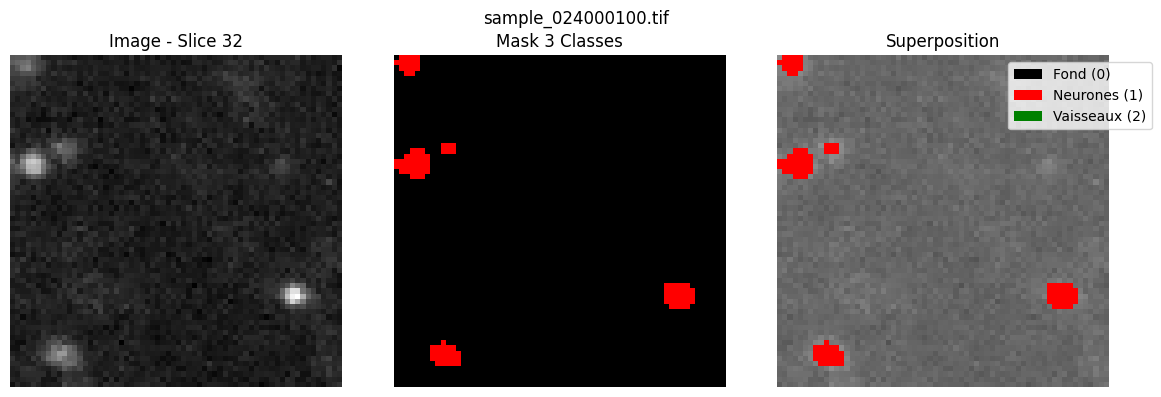

  Classe 0: 257,719
  Classe 1: 4,425
  Classe 2: 0

--- Patch 884: sample_013000036.tif ---


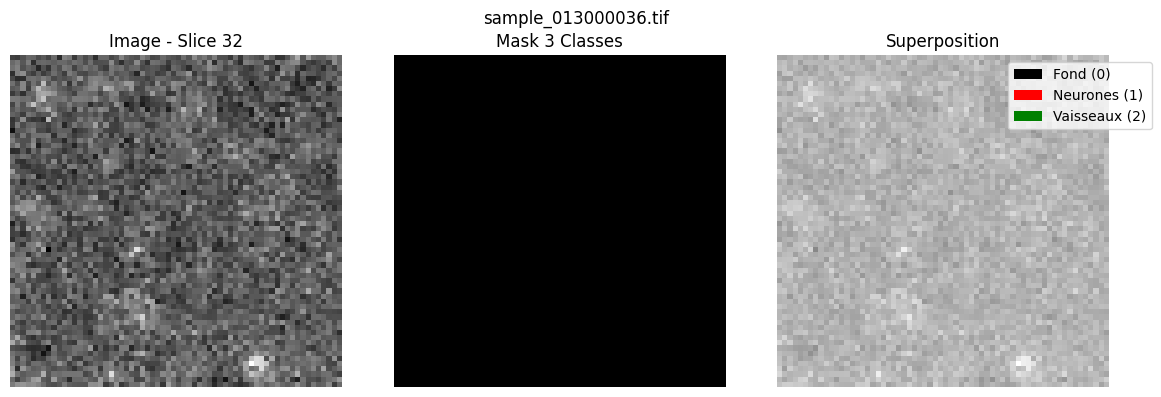

  Classe 0: 262,105
  Classe 1: 39
  Classe 2: 0

--- Patch 1599: sample_020000399.tif ---


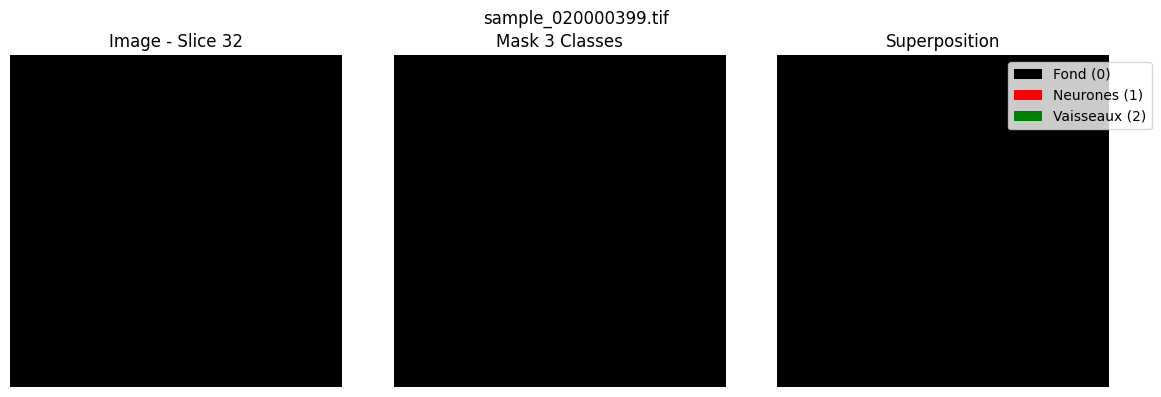

  Classe 0: 262,122
  Classe 1: 22
  Classe 2: 0

--- Patch 1020: sample_015000029.tif ---


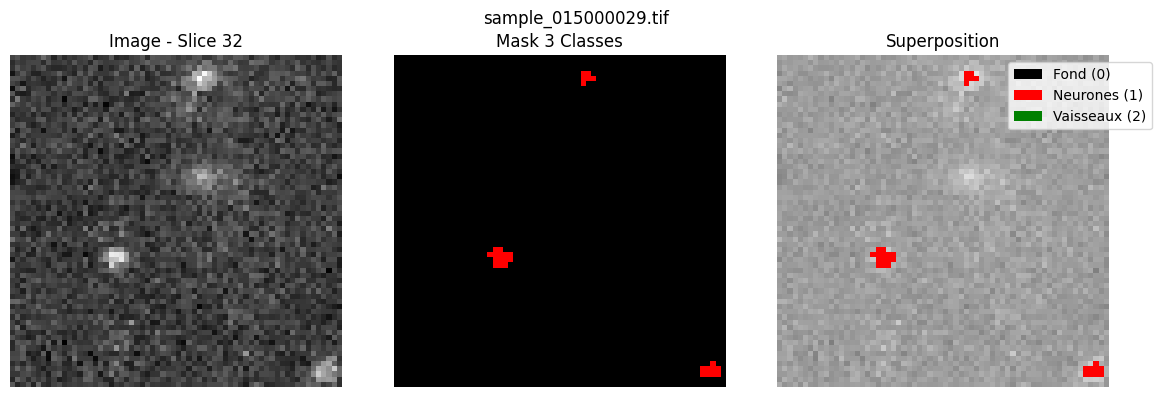

  Classe 0: 261,627
  Classe 1: 517
  Classe 2: 0

--- Patch 2322: sample_026000071.tif ---


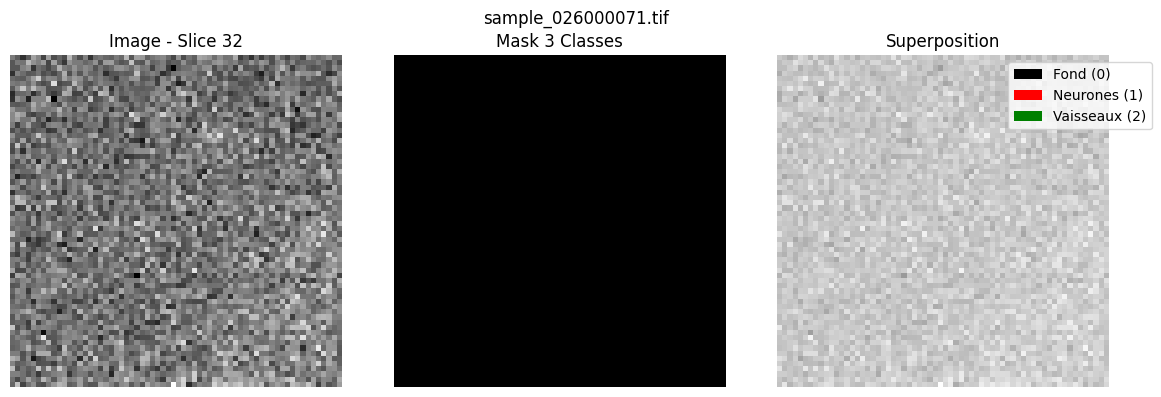

  Classe 0: 262,126
  Classe 1: 18
  Classe 2: 0

--- Patch 359: sample_005000078.tif ---


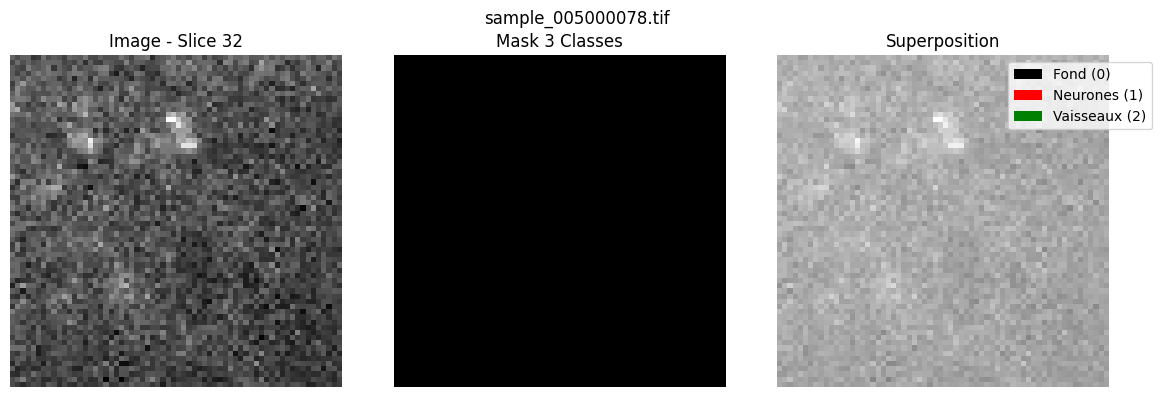

  Classe 0: 261,113
  Classe 1: 1,031
  Classe 2: 0

--- Patch 1592: sample_020000391.tif ---


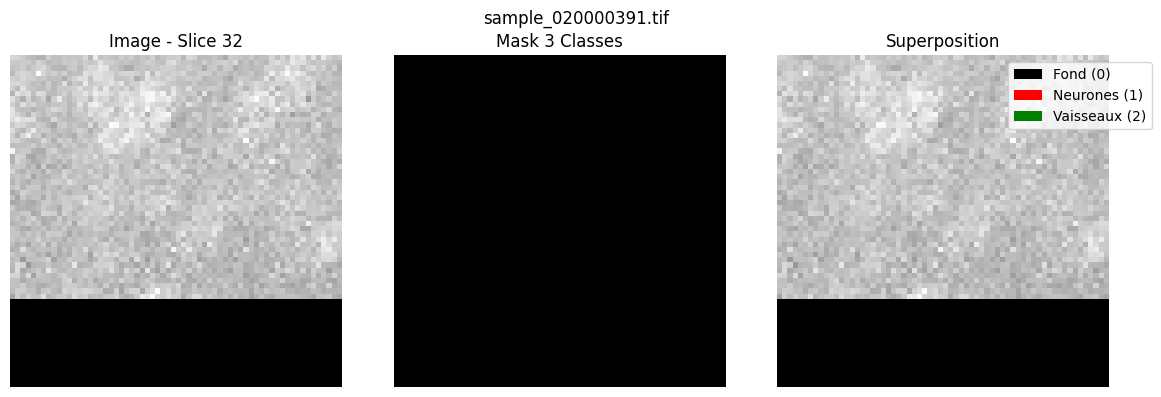

  Classe 0: 261,805
  Classe 1: 339
  Classe 2: 0

--- Patch 1694: sample_021000025.tif ---


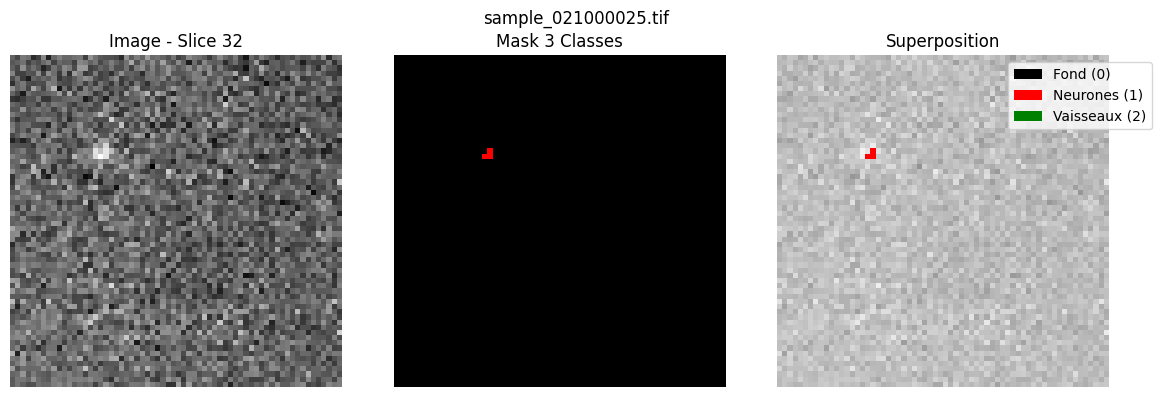

  Classe 0: 261,794
  Classe 1: 350
  Classe 2: 0


In [15]:
print("Visualisation de patches aléatoires")
print("-" * 40)

random_indices = random.sample(selected_indices, min(20, len(selected_indices)))

for idx in random_indices:
    print(f"\n--- Patch {idx}: {image_files[idx].name} ---")
    show_patch_3class(image_files[idx], mask_files[idx])

In [7]:
print("\nAnalyse des classes...")
print("-" * 40)

total_voxels = 0
total_c0 = 0
total_c1 = 0
total_c2 = 0

for i, idx in enumerate(selected_indices):
    mask_file = mask_files[idx]
    mask_sitk = read_tif_image(str(mask_file))
    mask = convert_image_to_array(mask_sitk)
    
    total_voxels += mask.size
    total_c0 += (mask == 0).sum()
    total_c1 += (mask == 1).sum()
    total_c2 += (mask == 2).sum()
    
    if (i + 1) % 500 == 0:
        print(f"  Analysé {i+1}/{len(selected_indices)} patches")

print(f"\n✅ Analyse terminée!")


Analyse des classes...
----------------------------------------
  Analysé 500/2500 patches
  Analysé 1000/2500 patches
  Analysé 1500/2500 patches
  Analysé 2000/2500 patches
  Analysé 2500/2500 patches

✅ Analyse terminée!


In [8]:
pct0 = (total_c0 / total_voxels) * 100
pct1 = (total_c1 / total_voxels) * 100
pct2 = (total_c2 / total_voxels) * 100

print("=" * 50)
print("RÉSULTATS - DISTRIBUTION DES CLASSES")
print("=" * 50)
print(f"Patches analysés: {len(selected_indices):,}")
print(f"Total voxels: {total_voxels:,}")
print()
print(f"Classe 0 (Fond):        {pct0:.2f}%  ({total_c0:,} voxels)")
print(f"Classe 1 (Neurones):    {pct1:.4f}%  ({total_c1:,} voxels)")
print(f"Classe 2 (Vaisseaux):   {pct2:.4f}%  ({total_c2:,} voxels)")
print()
print(f"Ratio Fond/Neurones:     {total_c0/total_c1:.1f}")
print(f"Ratio Fond/Vaisseaux:    {total_c0/total_c2:.1f}")

RÉSULTATS - DISTRIBUTION DES CLASSES
Patches analysés: 2,500
Total voxels: 655,360,000

Classe 0 (Fond):        99.60%  (652,736,172 voxels)
Classe 1 (Neurones):    0.2227%  (1,459,306 voxels)
Classe 2 (Vaisseaux):   0.1777%  (1,164,522 voxels)

Ratio Fond/Neurones:     447.3
Ratio Fond/Vaisseaux:    560.5


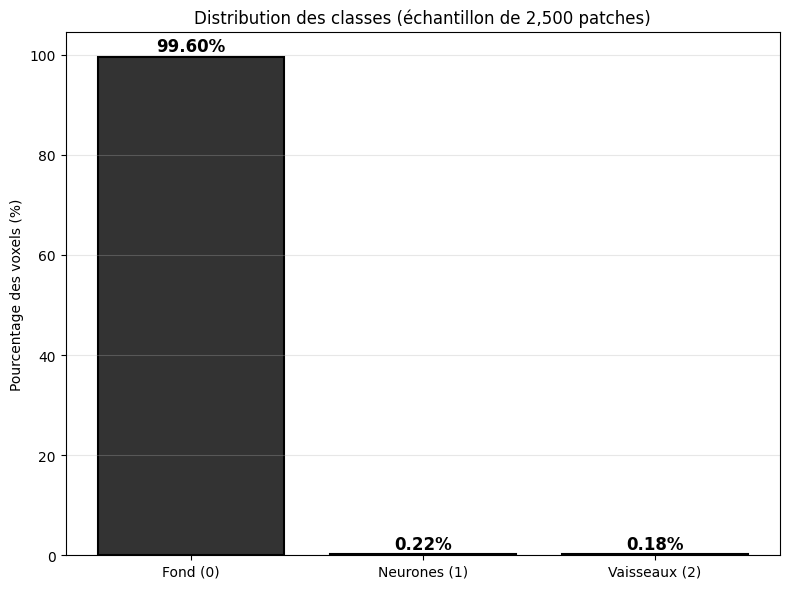

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))

classes = ['Fond (0)', 'Neurones (1)', 'Vaisseaux (2)']
percentages = [pct0, pct1, pct2]
colors = ['#333333', '#FF4444', '#44AA44']

bars = ax.bar(classes, percentages, color=colors, edgecolor='black', linewidth=1.5)

for bar, pct in zip(bars, percentages):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{pct:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylabel('Pourcentage des voxels (%)')
ax.set_title(f'Distribution des classes (échantillon de {len(selected_indices):,} patches)')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

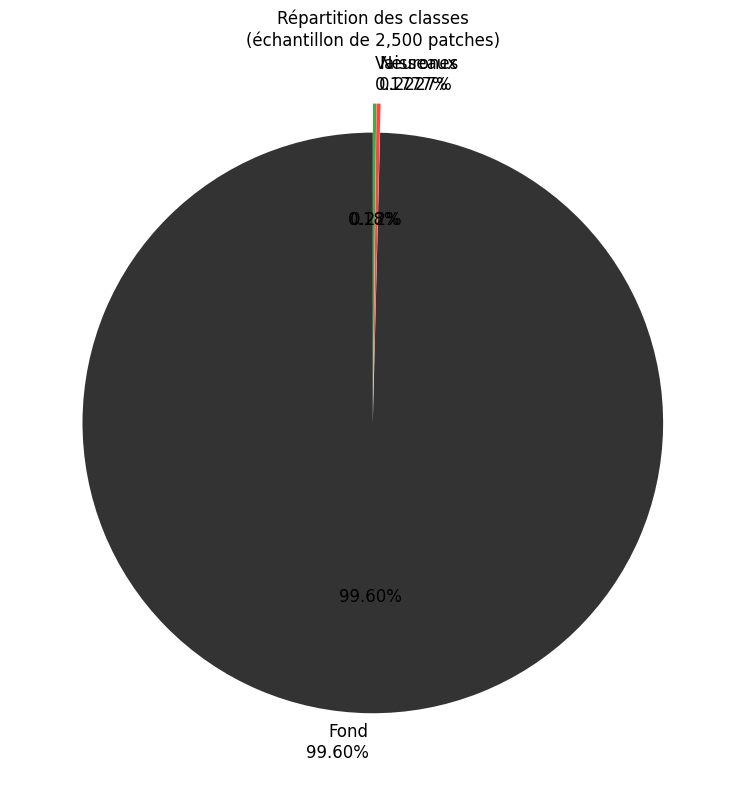

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))

labels = [f'Fond\n{pct0:.2f}%', f'Neurones\n{pct1:.4f}%', f'Vaisseaux\n{pct2:.4f}%']
colors = ['#333333', '#FF4444', '#44AA44']
explode = (0.02, 0.08, 0.08)

wedges, texts, autotexts = ax.pie(
    percentages, 
    labels=labels, 
    colors=colors, 
    explode=explode,
    autopct='%1.2f%%',
    startangle=90,
    textprops={'fontsize': 12}
)

ax.set_title(f'Répartition des classes\n(échantillon de {len(selected_indices):,} patches)')
plt.tight_layout()
plt.show()

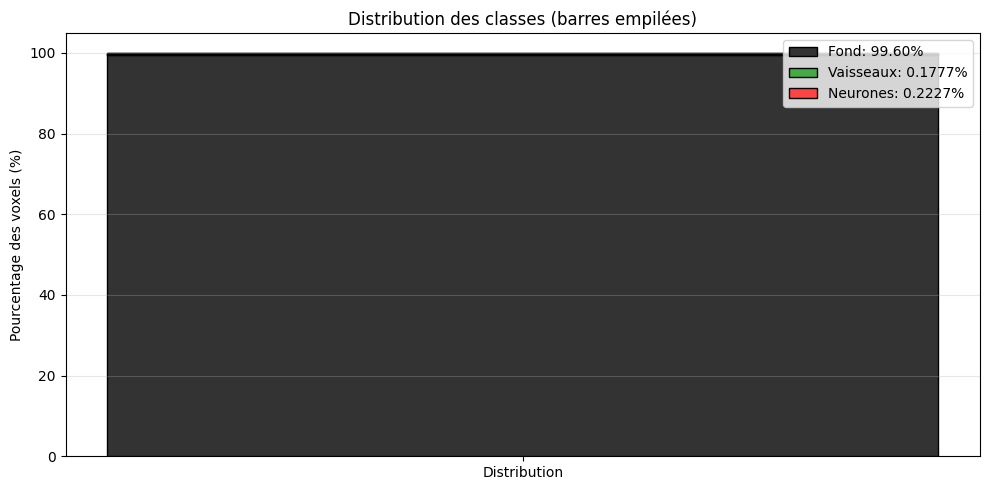

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(['Distribution'], [100], color='#333333', edgecolor='black', 
       label=f'Fond: {pct0:.2f}%')
ax.bar(['Distribution'], [pct1 + pct2], bottom=[pct0], color='#44AA44', 
       edgecolor='black', label=f'Vaisseaux: {pct2:.4f}%')
ax.bar(['Distribution'], [pct1], bottom=[pct0], color='#FF4444', 
       edgecolor='black', label=f'Neurones: {pct1:.4f}%')

ax.set_ylabel('Pourcentage des voxels (%)')
ax.set_title('Distribution des classes (barres empilées)')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [13]:
print("\n" + "=" * 50)
print("RÉSUMÉ FINAL - DATASET FILTRÉ")
print("=" * 50)

print(f"Total patches filtrés: {len(image_files):,}")
print(f"Patches analysés: {len(selected_indices):,}")
print()
print(f"Classe 0 (Fond):        {pct0:.2f}%")
print(f"Classe 1 (Neurones):    {pct1:.4f}%")
print(f"Classe 2 (Vaisseaux):   {pct2:.4f}%")
print()
print(f"Ratio Fond/Neurones:     {total_c0/total_c1:.1f}")
print(f"Ratio Fond/Vaisseaux:    {total_c0/total_c2:.1f}")

if pct1 < 0.5:
    print("\n⚠️ Déséquilibre fort: Neurones < 0.5% des voxels")
    print("   Utiliser Dice Loss ou Tversky Loss")
else:
    print("\n✅ Déséquilibre acceptable")




RÉSUMÉ FINAL - DATASET FILTRÉ
Total patches filtrés: 2,550
Patches analysés: 2,500

Classe 0 (Fond):        99.60%
Classe 1 (Neurones):    0.2227%
Classe 2 (Vaisseaux):   0.1777%

Ratio Fond/Neurones:     447.3
Ratio Fond/Vaisseaux:    560.5

⚠️ Déséquilibre fort: Neurones < 0.5% des voxels
   Utiliser Dice Loss ou Tversky Loss
